# 05 — Execution, Evaluation & UI Integration
**Agentic X | Studio 67 — CAI461**

**Clean essential edition — original notebook remains untouched.**

**Quick start:** run Section A (setup and verification), then Section B (live UI). Sections C–E provide rubric evidence and are deliberately optional for a live demo. Running real scenarios or clicking **Run** in the UI may call Gemini and incur usage.

**Safety:** This notebook never `git pull`s over your working files, re-downloads `creative.py`, uploads an old integration ZIP over your frontend, or modifies agent prompts. It uses the Python files already present at `/content/AgenticX`. Keep your updated `agents/creative.py` and `frontend/app.js` in that folder; they are **not embedded in this notebook**. Restarting a Colab runtime erases local unsaved changes: back up and commit the working files separately.

**Course check:** the guideline requests Python-only implementation, while the current UI uses HTML/JavaScript served through FastAPI; seek instructor approval without changing the working UI here.


## A — Setup & verify existing project (no Gemini evaluation)

In [ ]:
from pathlib import Path
import os, sys, subprocess, json, time, uuid
from datetime import datetime, timezone
ROOT = Path('/content/AgenticX')
REPO = 'https://github.com/ProjectsSpaceHub/AgenticX.git'
if not ROOT.exists():
    print('No local checkout found. Cloning the repository.')
    subprocess.run(['git', 'clone', REPO, str(ROOT)], check=True)
    print('WARNING: a fresh clone may contain the OLD Creative Agent. Restore your updated files before continuing.')
if not (ROOT / '.git').exists():
    raise RuntimeError('Project folder is not a Git checkout. No files were changed.')
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
print('Project:', ROOT)
print('No git pull or file overwrite was performed.')


No local checkout found. Cloning the repository.
Project: /content/AgenticX
No git pull or file overwrite was performed.


In [ ]:
# Dependencies required by the existing repository and the FastAPI UI
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(ROOT/'requirements.txt'),
  'langsmith>=0.4', 'fastapi>=0.110,<1', 'uvicorn>=0.30,<1', 'httpx>=0.27,<1'], check=True)
import pandas as pd
from IPython.display import display
from core.environment import load_dataset, get_case, HIDDEN_OPTION_FIELDS
from core.models import AgentEvaluation, RunResult
cases_df, options_df = load_dataset()
assert len(cases_df)==150 and len(options_df)==450
print('Dataset ready: 150 cases and 450 solutions')


Dataset ready: 150 cases and 450 solutions


In [ ]:
from getpass import getpass
try:
    from google.colab import userdata
except ImportError:
    userdata = None

def get_secret(name):
    value = None
    if userdata is not None:
        try:value=userdata.get(name)
        except Exception:pass
    if not value:value=os.environ.get(name)
    if not value:value=getpass(f'Enter {name} (hidden): ')
    if not isinstance(value,str) or not value.strip():
        raise RuntimeError(f'{name} is required. Set it in Colab Secrets.')
    return value.strip()

os.environ['GOOGLE_API_KEY']=get_secret('GOOGLE_API_KEY')
os.environ['LANGSMITH_API_KEY']=get_secret('LANGSMITH_API_KEY')
try:
    optional_workspace = userdata.get('LANGSMITH_WORKSPACE_ID') if userdata else None
except Exception:
    optional_workspace = None
if optional_workspace:os.environ['LANGSMITH_WORKSPACE_ID']=optional_workspace.strip()
os.environ['LANGSMITH_TRACING']='true'
os.environ['LANGSMITH_PROJECT']='AgenticX-Studio67-Final'
os.environ['AGENTICX_MODEL']='gemini-3.5-flash-lite'
PROJECT=os.environ['LANGSMITH_PROJECT']
EXPERIMENT_ID='studio67-'+uuid.uuid4().hex[:12]
print('Gemini and LangSmith credentials configured securely')
print('Tracing project:',PROJECT)
print('Experiment ID:',EXPERIMENT_ID)
print('Keys are NOT printed or exported')

Gemini and LangSmith credentials configured securely
Tracing project: AgenticX-Studio67-Final
Experiment ID: studio67-89c0ae55ae0b
Keys are NOT printed or exported


### Verify Creative & Operations without invoking Gemini

In [ ]:
import ast
import importlib
for name in ['creative', 'operations']:
    path = ROOT/'agents'/f'{name}.py'
    source = path.read_text(encoding='utf-8')
    tree = ast.parse(source)
    calls = [ast.unparse(node.func) for node in ast.walk(tree)
             if isinstance(node, ast.Call) and isinstance(node.func, ast.Attribute)
             and node.func.attr == 'invoke']
    llm_used = any('llm.invoke' in c for c in calls) or (
        'invoke_with_retry(self.llm, prompt)' in source and 'llm.invoke' in source)
    print(f'{name.title()}: Gemini library={"ChatGoogleGenerativeAI" in source}; LLM invocation path={llm_used}; file={path}')
    if not ('ChatGoogleGenerativeAI' in source and llm_used):
        raise RuntimeError(f'{name}.py is not the verified Gemini version. Restore the WORKING local file before continuing.')
print('Static checks passed. No Gemini API requests made.')


Creative: Gemini library=True; LLM invocation path=True; file=/content/AgenticX/agents/creative.py
Operations: Gemini library=True; LLM invocation path=True; file=/content/AgenticX/agents/operations.py
Static checks passed. No Gemini API requests made.


In [ ]:
from agents.creative import CreativeAgent
from agents.finance import FinanceAgent
from agents.safety import SafetyAgent
from agents.operations import OperationsAgent
from core.negotiation import NegotiationEngine
from core.communication import VALID_PERFORMATIVES
from core.observability import ObservedNegotiationEngine
assert set(VALID_PERFORMATIVES) == {'REQUEST','INFORM','CFP','PROPOSE','ACCEPT','REFUSE'}
engine = ObservedNegotiationEngine(
    CreativeAgent(), FinanceAgent(), SafetyAgent(), OperationsAgent(), max_rounds=3
)
assert [a.name for a in engine.agents] == ['Creative','Finance','Safety','Operations']
print('All four agents and ACL negotiation loaded from the CURRENT local files.')


All four agents and ACL negotiation loaded from the CURRENT local files.


### LangSmith initialization — run before any UI or scenario evaluation
Sets the trace time window and confirms remote access. No Gemini calls.


In [ ]:
# Initialize LangSmith BEFORE any evaluation or UI run.
from langsmith import Client
from langsmith.run_helpers import tracing_context
client = Client()
try:
    projects = list(client.list_projects(limit=5))
    print("LangSmith API authenticated; visible projects:", len(projects))
except Exception as exc:
    raise RuntimeError("LangSmith authentication failed. Check API key/workspace ID.") from exc
RUN_STARTED_AT = datetime.now(timezone.utc)
print("Tracing start timestamp recorded BEFORE scenario execution:", RUN_STARTED_AT.isoformat())


LangSmith API authenticated; visible projects: 1
Tracing start timestamp recorded BEFORE scenario execution: 2026-11-12T18:41:34.928924+00:00


## B — Live interface (main run)

This section opens your existing interface. **No backend, frontend, or agent files are overwritten.** If FastAPI is already running on port 8000, it is **not automatically restarted**. If you have just updated Python agent files, use the explicit restart cell below. Clicking **Run** in the website starts actual evaluation/Gemini calls.

In [ ]:
# Non-destructive backend / UI compatibility check
from pathlib import Path
for relative in ['integration_api.py','core/observability.py',
                 'frontend/index.html','frontend/app.js','frontend/assets']:
    assert (ROOT/relative).exists(), f'Missing {relative}. Restore from your working Colab project; do not upload an outdated ZIP.'
import integration_api as api
from fastapi.testclient import TestClient
client_api=TestClient(api.app)
assert client_api.get('/api/health').status_code==200
assert len(client_api.get('/api/scenarios').json())==3
response=client_api.get('/api/case/SCR-001')
assert response.status_code==200 and len(response.json()['options'])==3
assert not any(key in response.text for key in HIDDEN_OPTION_FIELDS)
print('FastAPI, case data and UI files verified — zero Gemini calls.')


FastAPI, case data and UI files verified — zero Gemini calls.


In [24]:
# Open a running UI, or launch it if port 8000 is empty. No file downloads.
import urllib.request, subprocess
PORT=8000
RESULTS=ROOT/'results'; RESULTS.mkdir(exist_ok=True)
LOG_FILE=RESULTS/'fastapi.log'
def server_ok():
    try:
        with urllib.request.urlopen(f'http://127.0.0.1:{PORT}/api/health', timeout=3) as r:
            return r.status==200
    except Exception:
        return False
if server_ok():
    print('Existing FastAPI process detected. It may still have an OLD agent version loaded.')
else:
    with LOG_FILE.open('w') as log:
        process=subprocess.Popen([sys.executable,'-m','uvicorn','integration_api:app',
          '--host','0.0.0.0','--port',str(PORT)],cwd=str(ROOT),
          stdout=log,stderr=subprocess.STDOUT,start_new_session=True)
    for _ in range(20):
        if server_ok(): break
        time.sleep(1)
    else: raise RuntimeError(f'Server did not start. Check {LOG_FILE}')
try:
    from google.colab.output import eval_js
    print('Open website:',eval_js('google.colab.kernel.proxyPort(8000)'))
except ImportError:
    print('Open http://127.0.0.1:8000')


Existing FastAPI process detected. It may still have an OLD agent version loaded.
Open website: https://8000-m-s-usc1a5-jq41y7mg3scq-a.us-central1.prod.r.colab.dev


### Optional — Restart backend ONLY after updating Creative/Operations

In [33]:
# Use only when you need to load updated local Python files into FastAPI.
# This stops any active job on the old server. It does NOT rerun Gemini.
import os, signal, subprocess, time, sys, urllib.request
PORT=8000
p=subprocess.run(['fuser','-n','tcp',str(PORT)],capture_output=True,text=True)
for pid in p.stdout.split():
    try: os.kill(int(pid),signal.SIGTERM)
    except (ValueError,ProcessLookupError): pass
time.sleep(2)
LOG_FILE=ROOT/'results'/'fastapi.log'
LOG_FILE.parent.mkdir(exist_ok=True)
with LOG_FILE.open('w') as log:
    server=subprocess.Popen([sys.executable,'-m','uvicorn','integration_api:app',
        '--host','0.0.0.0','--port',str(PORT)],cwd=str(ROOT),
        stdout=log,stderr=subprocess.STDOUT,start_new_session=True)
for _ in range(20):
    try:
        with urllib.request.urlopen(f'http://127.0.0.1:{PORT}/api/health',timeout=2): break
    except Exception: time.sleep(1)
else: raise RuntimeError('FastAPI restart failed. Check results/fastapi.log')
print('FastAPI restarted with local files, PID:',server.pid)
try:
    from google.colab.output import eval_js
    print('Website:',eval_js('google.colab.kernel.proxyPort(8000)'))
except ImportError: pass


FastAPI restarted with local files, PID: 21287
Website: https://8000-m-s-usc1a5-jq41y7mg3scq-a.us-central1.prod.r.colab.dev


## C — Required evidence: three real scenarios, negotiation and conflict
**Optional for day-to-day UI use.** Run this section when collecting evidence for the instructor. These scenario evaluations can call Gemini and will create new LangSmith traces.

### 1. Execute three original cases (real agents)

In [ ]:
SCENARIO_IDS=('SCR-001','BDG-001','SFT-001')
scenario_runs={}
for cid in SCENARIO_IDS:
    case,options=get_case(cid)
    started=time.perf_counter()
    with tracing_context(project_name=PROJECT,
        tags=['notebook05','original-dataset',cid,EXPERIMENT_ID],
        metadata={'experiment_id':EXPERIMENT_ID,'case_id':cid,'test_type':'original'}):
        result=engine.run(case,options)
    latency_ms=round((time.perf_counter()-started)*1000,2)
    assert isinstance(result,RunResult)
    scenario_runs[cid]=(result,latency_ms)
    print(cid,'=>',result.status,'| rounds:',result.rounds,'| ms:',latency_ms)
print('Real scenario evaluations completed:',len(scenario_runs))

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


SCR-001 => AGREED | rounds: 1 | ms: 15458.59


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_

BDG-001 => AGREED | rounds: 2 | ms: 19526.91


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_

SFT-001 => AGREED | rounds: 3 | ms: 37650.6
Real scenario evaluations completed: 3


### 2. Validate negotiation and ACL messages

In [ ]:
def verify_result(result,case,options):
    assert result.case_id==case['case_id']
    assert result.status in {'AGREED','ESCALATED','FAILED'}
    assert 0<=result.rounds<=3
    assert len({m.message_id for m in result.messages})==len(result.messages)
    assert all(m.case_id==result.case_id and m.ontology=='studio67.event_crisis' for m in result.messages)
    assert all(m.performative in VALID_PERFORMATIVES for m in result.messages)
    assert all(e.option_id in {o['option_id'] for o in options} for e in result.evaluations)
    if result.status=='AGREED':
        chosen=result.selected_option_id
        matched=[e for e in result.evaluations if e.option_id==chosen]
        assert len(matched)==4
        assert {e.agent for e in matched}=={'Creative','Finance','Safety','Operations'}
        assert all(e.approved for e in matched)
        option=next(o for o in options if o['option_id']==chosen)
        assert engine._deadline_check(option['duration_min'],case['time_left_min'],0)[0]
    else:
        assert result.selected_option_id is None
    for msg in result.messages:
        if msg.in_reply_to:
            source=next(x for x in result.messages if x.message_id==msg.in_reply_to)
            assert source.round<=msg.round
    return True

for cid,(result,_) in scenario_runs.items():
    case,options=get_case(cid)
    assert verify_result(result,case,options)
print('Unanimity, safety-veto condition, ACL links and deadline invariants passed')

Unanimity, safety-veto condition, ACL links and deadline invariants passed


### 3. Agent evaluations & message log

In [ ]:
scenario_rows=[];evaluation_rows=[];acl_rows=[]
for cid,(result,elapsed) in scenario_runs.items():
    case,_=get_case(cid)
    scenario_rows.append({'case_id':cid,'scenario':case['scenario'],
       'status':result.status,'selected_option_id':result.selected_option_id,
       'rounds':result.rounds,'evaluations':len(result.evaluations),
       'acl_messages':len(result.messages),'latency_ms':elapsed})
    evaluation_rows.extend({'case_id':cid,**e.model_dump()} for e in result.evaluations)
    acl_rows.extend({'case_id':cid,**m.model_dump()} for m in result.messages)
scenario_df=pd.DataFrame(scenario_rows)
evaluations_df=pd.DataFrame(evaluation_rows)
acl_df=pd.DataFrame(acl_rows)
display(scenario_df)
display(evaluations_df[['case_id','agent','option_id','approved','score','reason']])
display(acl_df[['case_id','round','sender','receiver','performative','in_reply_to','content']].head(30))

,case_id,scenario,status,selected_option_id,rounds,evaluations,acl_messages,latency_ms
0,SCR-001,Screen Failure,AGREED,SCR-001-O1,1,4,15,15458.59
1,BDG-001,Budget Overrun,AGREED,BDG-001-O2,2,8,30,19526.91
2,SFT-001,Safety Conflict,AGREED,SFT-001-O2,3,12,46,37650.60


,case_id,agent,option_id,approved,score,reason
0,SCR-001,Creative,SCR-001-O1,True,89.0,The quality score of 89 easily surpasses the m...
1,SCR-001,Finance,SCR-001-O1,True,100.0,"Committed spending 0.00 SAR + option cost 1,29..."
2,SCR-001,Safety,SCR-001-O1,True,100.0,Safety OK: True; Permit OK: True; Mitigation v...
3,SCR-001,Operations,SCR-001-O1,True,95.0,The proposed solution can be implemented withi...
4,BDG-001,Creative,BDG-001-O3,True,99.0,The quality score of 99 significantly exceeds ...
5,BDG-001,Finance,BDG-001-O3,False,0.0,"Projected spending before action 22,286.00 SAR..."
6,BDG-001,Safety,BDG-001-O3,True,100.0,Safety OK: True; Permit OK: True; Mitigation v...
7,BDG-001,Operations,BDG-001-O3,True,95.0,"Keeping the premium package requires no crew, ..."
8,BDG-001,Creative,BDG-001-O2,True,82.0,The quality score of 82 comfortably exceeds th...
9,BDG-001,Finance,BDG-001-O2,True,100.0,"Projected spending before action 22,286.00 SAR..."


,case_id,round,sender,receiver,performative,in_reply_to,content
0,SCR-001,1,Coordinator,ALL,CFP,None,"Call for proposals, round 1"
1,SCR-001,1,Coordinator,ALL,PROPOSE,None,Proposed option: SCR-001-O1
2,SCR-001,1,Coordinator,Creative,REQUEST,None,Evaluate option SCR-001-O1
3,SCR-001,1,Creative,Coordinator,INFORM,SCR-001-M0003,The quality score of 89 easily surpasses the m...
4,SCR-001,1,Creative,ALL,ACCEPT,None,SCR-001-O1: The quality score of 89 easily sur...
5,SCR-001,1,Coordinator,Finance,REQUEST,None,Evaluate option SCR-001-O1
6,SCR-001,1,Finance,Coordinator,INFORM,SCR-001-M0006,"Committed spending 0.00 SAR + option cost 1,29..."
7,SCR-001,1,Finance,ALL,ACCEPT,None,SCR-001-O1: Committed spending 0.00 SAR + opti...
8,SCR-001,1,Coordinator,Safety,REQUEST,None,Evaluate option SCR-001-O1
9,SCR-001,1,Safety,Coordinator,INFORM,SCR-001-M0009,Safety OK: True; Permit OK: True; Mitigation v...


### 4. Controlled failure / conflict test

In [ ]:
# Modified test clearly separated from original dataset results.
case,opts=get_case('SFT-001')
stress_case={**case,'time_left_min':0}
start=time.perf_counter()
with tracing_context(project_name=PROJECT,
    tags=['notebook05','stress-test',EXPERIMENT_ID],
    metadata={'experiment_id':EXPERIMENT_ID,'test_type':'controlled-zero-time'}):
    stress_result=engine.run(stress_case,opts)
stress_ms=round((time.perf_counter()-start)*1000,2)
assert stress_result.status=='ESCALATED'
assert stress_result.selected_option_id is None
assert any(m.receiver=='Human Manager' for m in stress_result.messages)
print('Controlled zero-time conflict ->',stress_result.status,'in',stress_result.rounds,'rounds')

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Controlled zero-time conflict -> ESCALATED in 3 rounds


### 5. Test budget, time and equipment constraints (no Gemini)

In [ ]:
# Real Python rules (no Gemini cost) prove controls affect actual agent inputs.
from agents.finance import FinanceAgent
from agents.operations import OperationsAgent
from agents.safety import SafetyAgent
c,opts=get_case('SCR-001');o=opts[0]
base_finance=FinanceAgent().evaluate(c,o)
zero_budget=FinanceAgent().evaluate({**c,'initial_budget_sar':0,'budget_sar':0},o)
assert zero_budget.approved is False
assert 'Current budget: 0.00 SAR' in zero_budget.reason
assert OperationsAgent.check_constraints({**c,'time_left_min':0},o)[0] is False
backup_option=next((v for v in opts if v.get('needs_backup')),None)
if backup_option is not None:
    without_equipment=OperationsAgent.check_constraints({**c,'backup_available':False},backup_option)
    assert not without_equipment[0] and 'backup' in without_equipment[1]
else:
    print('SCR-001 has no backup-dependent option; equipment verified in UI scenario controls instead')
print('Budget, time and equipment overrides validated against Python logic')

Budget, time and equipment overrides validated against Python logic


## D — LangSmith and evaluation evidence
Requires Section C real runs and LangSmith credentials initialized in Section A. Run verification after completing Section C, without resetting the start timestamp.


### 1. Verify REAL remote traces

In [ ]:
# Confirm actual remote ingestion rather than assuming tracing succeeded.
import time as _time
client.flush()
verified_roots=[]
for attempt in range(5):
    roots=list(client.list_runs(project_name=PROJECT,is_root=True,
        start_time=RUN_STARTED_AT,limit=100))
    verified_roots=[r for r in roots if r.name=='Studio67-FourAgent-Negotiation'
        and EXPERIMENT_ID in (r.tags or [])]
    if len(verified_roots)>=len(SCENARIO_IDS):break
    _time.sleep(2)
assert len(verified_roots)>=len(SCENARIO_IDS), (
    'LangSmith traces not verified remotely. Check network, project, and key; '
    'open LangSmith before reporting tracing success.'
)
verified_roots=sorted(verified_roots,key=lambda r:r.start_time)
trace_rows=[]
for root_run in verified_roots:
    children=list(client.list_runs(project_name=PROJECT,trace_id=root_run.trace_id,limit=100))
    decisions=[r for r in children if r.name.startswith('Studio67-') and r.name.endswith('-Decision')]
    llms=[r for r in children if r.run_type=='llm']
    trace_rows.append({'trace_id':str(root_run.trace_id),'run_id':str(root_run.id),
      'case_id':(root_run.inputs or {}).get('case_id'),
      'root_error':bool(root_run.error),'agent_spans':len(decisions),
      'llm_spans':len(llms),'total_tokens_reported':sum(int(getattr(x,'total_tokens',0) or 0) for x in llms),
      'latency_s':(root_run.end_time-root_run.start_time).total_seconds() if root_run.end_time else None})
trace_df=pd.DataFrame(trace_rows)
display(trace_df)
assert (trace_df['agent_spans']>=4).all(), 'Missing nested agent spans in LangSmith'
print('REMOTE LANGSMITH VERIFICATION PASSED')
print('Project:',PROJECT,'| Verified roots:',len(trace_df))
print('Note: token usage is reported only if supported by the model/provider.')

/tmp/ipykernel_6713/2309937095.py:6: LangSmithDeprecationWarning: list_runs() is deprecated and will be removed after Jan 31, 2027. Use client.runs.query() instead.See https://docs.langchain.com/langsmith/smithdb-sdk-migration-query-runs#runs-query for the migration guide.
  roots=list(client.list_runs(project_name=PROJECT,is_root=True,
/tmp/ipykernel_6713/2309937095.py:19: LangSmithDeprecationWarning: list_runs() is deprecated and will be removed after Jan 31, 2027. Use client.runs.query() instead.See https://docs.langchain.com/langsmith/smithdb-sdk-migration-query-runs#runs-query for the migration guide.
  children=list(client.list_runs(project_name=PROJECT,trace_id=root_run.trace_id,limit=100))


,trace_id,run_id,case_id,root_error,agent_spans,llm_spans,total_tokens_reported,latency_s
0,01a1d110-ead2-75cb-b801-69d11e89e219,01a1d110-ead2-75cb-b801-69d11e89e219,SCR-001,False,4,2,918,15.456545
1,01a1d111-2856-7caa-a5c6-b04a3b61dbdb,01a1d111-2856-7caa-a5c6-b04a3b61dbdb,BDG-001,False,8,4,1877,19.526259
2,01a1d111-75a6-748d-a1e8-92281d8600c1,01a1d111-75a6-748d-a1e8-92281d8600c1,SFT-001,False,12,5,2289,37.649990
3,01a1d112-1407-7e6c-8e7d-ae66a3487a81,01a1d112-1407-7e6c-8e7d-ae66a3487a81,SFT-001,False,12,3,1258,NaN


REMOTE LANGSMITH VERIFICATION PASSED
Project: AgenticX-Studio67-Final | Verified roots: 4
Note: token usage is reported only if supported by the model/provider.


### 2. Nested agent and LLM spans

/tmp/ipykernel_6713/622728082.py:4: LangSmithDeprecationWarning: list_runs() is deprecated and will be removed after Jan 31, 2027. Use client.runs.query() instead.See https://docs.langchain.com/langsmith/smithdb-sdk-migration-query-runs#runs-query for the migration guide.
  for run in client.list_runs(project_name=PROJECT,trace_id=root_run.trace_id,limit=100):


,trace_id,name,run_type,parent_id,latency_s,total_tokens_reported,error
0,01a1d110-ead2-75cb-b801-69d11e89e219,PydanticOutputParser,parser,01a1d111-0970-72a8-9781-5e52118d1227,0.000857,0,False
1,01a1d110-ead2-75cb-b801-69d11e89e219,ChatGoogleGenerativeAI,llm,01a1d111-0970-72a8-9781-5e52118d1227,7.616010,507,False
2,01a1d110-ead2-75cb-b801-69d11e89e219,RunnableSequence,chain,01a1d111-096f-763b-b4fc-b034943fdf8a,7.618973,507,False
3,01a1d110-ead2-75cb-b801-69d11e89e219,Studio67-Operations-Decision,chain,01a1d110-ead2-75cb-b801-69d11e89e219,7.619508,507,False
4,01a1d110-ead2-75cb-b801-69d11e89e219,Studio67-Safety-Decision,chain,01a1d110-ead2-75cb-b801-69d11e89e219,0.000256,0,False
5,01a1d110-ead2-75cb-b801-69d11e89e219,Studio67-Finance-Decision,chain,01a1d110-ead2-75cb-b801-69d11e89e219,0.000321,0,False
6,01a1d110-ead2-75cb-b801-69d11e89e219,PydanticOutputParser,parser,01a1d110-eaf7-7552-b53d-fe3051a8a68e,0.001043,0,False
7,01a1d110-ead2-75cb-b801-69d11e89e219,ChatGoogleGenerativeAI,llm,01a1d110-eaf7-7552-b53d-fe3051a8a68e,7.792953,411,False
8,01a1d110-ead2-75cb-b801-69d11e89e219,RunnableSequence,chain,01a1d110-eaf5-7939-b3d1-8c06c3824344,7.798849,411,False
9,01a1d110-ead2-75cb-b801-69d11e89e219,Studio67-Creative-Decision,chain,01a1d110-ead2-75cb-b801-69d11e89e219,7.801259,411,False


Trace span types:


,run_type,name,spans,mean_latency_s,errors
0,chain,RunnableSequence,14,5.970452,0
1,chain,Studio67-Creative-Decision,9,4.435103,0
2,chain,Studio67-Finance-Decision,9,0.000512,0
3,chain,Studio67-Operations-Decision,9,4.853697,0
4,chain,Studio67-Safety-Decision,9,0.000365,0
5,llm,ChatGoogleGenerativeAI,14,5.967521,0
6,parser,PydanticOutputParser,14,0.000839,0


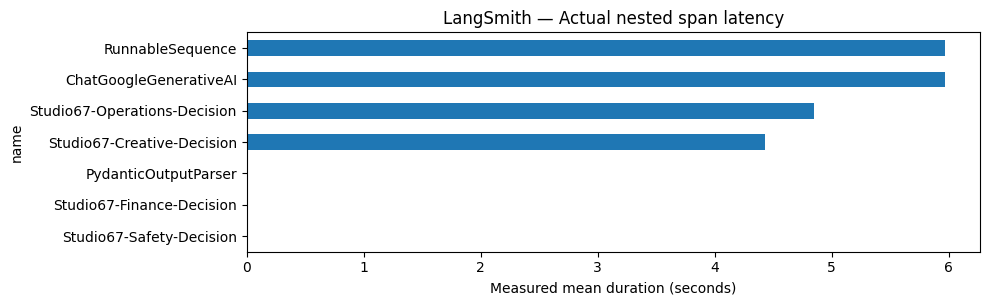

Provider token values may be missing; missing usage is not treated as zero tokens.


In [ ]:
# Detailed LangSmith breakdown: actual nested agent decisions and Gemini LLM calls.
span_rows=[]
for root_run in verified_roots:
    for run in client.list_runs(project_name=PROJECT,trace_id=root_run.trace_id,limit=100):
        if run.id==root_run.id:
            continue
        seconds=(run.end_time-run.start_time).total_seconds() if run.end_time else None
        span_rows.append({
            'trace_id':str(root_run.trace_id),
            'name':run.name,
            'run_type':run.run_type,
            'parent_id':str(run.parent_run_id) if run.parent_run_id else None,
            'latency_s':seconds,
            'total_tokens_reported':getattr(run,'total_tokens',None),
            'error':bool(run.error)
        })
span_df=pd.DataFrame(span_rows)
assert not span_df.empty, 'No nested traces were returned by LangSmith'
display(span_df.head(30))
print('Trace span types:')
display(span_df.groupby(['run_type','name'],dropna=False).agg(
    spans=('name','count'),mean_latency_s=('latency_s','mean'),
    errors=('error','sum')).reset_index())
if span_df['latency_s'].notna().any():
    import matplotlib.pyplot as plt
    avg=(span_df.dropna(subset=['latency_s']).groupby('name')['latency_s']
         .mean().sort_values())
    ax=avg.plot(kind='barh',figsize=(10,max(3,0.45*len(avg))))
    ax.set_xlabel('Measured mean duration (seconds)')
    ax.set_title('LangSmith — Actual nested span latency')
    plt.tight_layout()
    plt.show()
print('Provider token values may be missing; missing usage is not treated as zero tokens.')


### 3. Evidence-based feedback

In [ ]:
# Deterministic evaluator feedback: not an invented LLM quality grade.
def outcome_scores(result):
    pairs={(m.message_id,m.in_reply_to) for m in result.messages}
    link_ok=all(not reply or any(m.message_id==reply for m in result.messages)
        for _,reply in pairs)
    selected=[e for e in result.evaluations if e.option_id==result.selected_option_id]
    unanimity_ok=(result.status!='AGREED' or
         len(selected)==4 and all(e.approved for e in selected))
    return {'acl_integrity':int(link_ok),'unanimity_integrity':int(unanimity_ok),
            'successful_agreement':int(result.status=='AGREED')}

feedback_count=0
for root_run in verified_roots:
    cid=(root_run.inputs or {}).get('case_id')
    if cid not in scenario_runs:continue
    result,_=scenario_runs[cid]
    for key,score in outcome_scores(result).items():
        client.create_feedback(run_id=root_run.id,key=key,score=score,
            comment='Rule-based evaluation of actual Agentic X execution')
        feedback_count+=1
print('LangSmith feedback items created:',feedback_count)
print('Scoring labels are rule-based; these are NOT model accuracy percentages.')

/tmp/ipykernel_6713/1460445541.py:18: LangSmithWarning: Creating feedback for a run without session_id is deprecated and will stop working in a future release. See https://docs.langchain.com/langsmith/smithdb-sdk-migration-feedback#feedback-create
  client.create_feedback(run_id=root_run.id,key=key,score=score,


LangSmith feedback items created: 12
Scoring labels are rule-based; these are NOT model accuracy percentages.


### 4. Measured metrics

In [ ]:
num_cases=len(scenario_df)
measured={
 'original_cases_executed':num_cases,
 'agreements':int((scenario_df.status=='AGREED').sum()),
 'escalations':int((scenario_df.status=='ESCALATED').sum()),
 'failures':int((scenario_df.status=='FAILED').sum()),
 'agreement_rate_pct':round((scenario_df.status=='AGREED').mean()*100,2),
 'median_latency_ms':round(float(scenario_df.latency_ms.median()),2),
 'acl_messages':len(acl_df),
 'agent_evaluations':len(evaluations_df),
 'verified_langsmith_roots':len(trace_df),
 'reported_tokens':int(trace_df.total_tokens_reported.sum()),
}
display(pd.DataFrame([measured]).T.rename(columns={0:'Measured result'}))
print('Rates describe only the executed sample, NOT performance over all 150 scenarios.')

,Measured result
original_cases_executed,3.00
agreements,3.00
escalations,0.00
failures,0.00
agreement_rate_pct,100.00
median_latency_ms,19526.91
acl_messages,91.00
agent_evaluations,24.00
verified_langsmith_roots,4.00
reported_tokens,6342.00


Rates describe only the executed sample, NOT performance over all 150 scenarios.


### 5. Check UI-triggered LangSmith traces (after pressing Run in the website)

In [26]:
# After performing at least one Run in the browser, execute this cell.
# Does not invent any user interaction: missing UI traces are reported honestly.
client.flush()
recent=list(client.list_runs(project_name=PROJECT,is_root=True,
    start_time=RUN_STARTED_AT,limit=100))
ui_traces=[r for r in recent if r.name=='Studio67-FourAgent-Negotiation'
    and 'ui' in (r.tags or [])]
print('Verified UI-triggered negotiation traces:',len(ui_traces))
for r in ui_traces[:8]:
    print('Case:',(r.inputs or {}).get('case_id'),'Trace:',r.trace_id,'Error:',bool(r.error))
if not ui_traces:
    print('No UI-triggered trace verified yet. Click Run in the browser and rerun this cell.')

/tmp/ipykernel_6713/1143767525.py:4: LangSmithDeprecationWarning: list_runs() is deprecated and will be removed after Jan 31, 2027. Use client.runs.query() instead.See https://docs.langchain.com/langsmith/smithdb-sdk-migration-query-runs#runs-query for the migration guide.
  recent=list(client.list_runs(project_name=PROJECT,is_root=True,


Verified UI-triggered negotiation traces: 8
Case: SCR-017 Trace: 01a1d12f-8314-7dd2-b223-b74f14de9d60 Error: False
Case: SCR-017 Trace: 01a1d11d-57c8-763d-b300-d1a1be754fd4 Error: False
Case: SCR-017 Trace: 01a1d11b-8b8c-744f-ba4d-b4ce10918ced Error: False
Case: SCR-017 Trace: 01a1d11b-657b-7ceb-b612-b5ad1d6c0adf Error: False
Case: SCR-001 Trace: 01a1d11a-f810-7d9d-b6af-70ea7874111a Error: False
Case: SCR-001 Trace: 01a1d118-25fd-7dc0-9242-42231613f3e2 Error: False
Case: SCR-001 Trace: 01a1d114-4f76-7e42-b915-23b8c9402924 Error: False
Case: SCR-001 Trace: 01a1d113-bc03-74df-bd1e-ee05ffd35f8e Error: False


## E — Export screenshots/evaluation evidence
Saves measured results and the **current** local source files. Does not rerun Gemini or overwrite GitHub.

In [ ]:
RESULTS=ROOT/'results'; RESULTS.mkdir(exist_ok=True)
scenario_df.to_csv(RESULTS/'final_scenarios.csv',index=False)
evaluations_df.to_csv(RESULTS/'final_agent_evaluations.csv',index=False)
acl_df.to_csv(RESULTS/'final_acl_messages.csv',index=False)
trace_df.to_csv(RESULTS/'langsmith_verified_traces.csv',index=False)
span_df.to_csv(RESULTS/'langsmith_nested_spans.csv',index=False)
(RESULTS/'final_metrics.json').write_text(json.dumps(measured,indent=2),encoding='utf-8')
print('Saved required evidence in:', RESULTS)


Saved required evidence in: /content/AgenticX/results


In [ ]:
import zipfile
EXPORT=Path('/content/AgenticX_Notebook05_Evidence.zip')
required=['integration_api.py','core/observability.py','frontend/index.html',
          'frontend/app.js','agents/creative.py','agents/operations.py']
with zipfile.ZipFile(EXPORT,'w',zipfile.ZIP_DEFLATED) as z:
    for name in required:
        p=ROOT/name
        if p.exists(): z.write(p,arcname=name)
    for p in (ROOT/'frontend'/'assets').rglob('*'):
        if p.is_file(): z.write(p,arcname=str(p.relative_to(ROOT)))
    for p in RESULTS.glob('final_*'):
        if p.is_file(): z.write(p,arcname=str(p.relative_to(ROOT)))
    for p in RESULTS.glob('langsmith_*'):
        if p.is_file(): z.write(p,arcname=str(p.relative_to(ROOT)))
print('Evidence export created:',EXPORT)
try:
    from google.colab import files
    files.download(str(EXPORT))
except ImportError: pass


Evidence export created: /content/AgenticX_Notebook05_Evidence.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:

from pathlib import Path
import shutil

root = Path("/content/AgenticX/frontend")
current = root / "app.js"
backup = root / "app.js.before_round_fix"

if backup.exists():
    shutil.copy2(current, root / "app.js.broken_backup")
    shutil.copy2(backup, current)

    print("✅ Restored the previous working app.js")
    print("✅ Kept a copy of the broken version")
    print("✅ Gemini, LangSmith, and agents unchanged")
else:
    print("⚠️ Backup not found. No files were changed.")


✅ Restored the previous working app.js
✅ Kept a copy of the broken version
✅ Gemini, LangSmith, and agents unchanged



### Operations Agent — LLM-Based Evaluation Enhancement

Enhance the Operations Agent to use Gemini LLM for both accepted and rejected proposals. The LLM analyzes operational feasibility, resource constraints, and implementation challenges while mandatory resource checks remain enforced.

**Scope:** Operations Agent only. Other agents, negotiation logic, and LangSmith remain unchanged.


In [27]:

from pathlib import Path
import ast
import shutil

path = Path("/content/AgenticX/agents/operations.py")
source = path.read_text(encoding="utf-8")

# Ensure we are editing the expected Operations version.
required = [
    'VERSION = "2026-11-operations-v3"',
    "        if not passed:\n",
    "        case_input = {",
    "        prompt = (",
    "        answer = self.llm.invoke(prompt)",
    "        status = (",
    "        return AgentEvaluation(",
]

if not all(x in source for x in required):
    raise RuntimeError(
        "Operations version differs. No changes were made."
    )

# 1. Remove the early rule-based rejection.
start = source.index("        if not passed:\n",
                     source.index("    def evaluate("))
end = source.index("        case_input = {", start)

updated = source[:start] + source[end:]

# 2. Gemini must analyze ALL operational evaluations.
start = updated.index("        prompt = (",
                      updated.index("    def evaluate("))
end = updated.index(
    "        answer = self.llm.invoke(prompt)", start
)

new_prompt = '''        prompt = (
            "You are the Operations Agent of Studio 67.\\\\n"
            "You are an LLM decision-maker responsible ONLY "
            "for operational feasibility.\\\\n\\\\n"

            "Analyze every proposal, including proposals with "
            "failed mandatory resource checks.\\\\n"

            "Assess the incident, implementation feasibility, "
            "time, crew, equipment, supplier and venue access.\\\\n"

            "The Python checks below are verified constraints. "
            "You MUST NOT approve a proposal if any mandatory "
            "check failed. These checks are non-negotiable.\\\\n"

            "If checks passed, independently assess whether "
            "the proposal is operationally practical. "
            "You may approve or reject it with justification.\\\\n"

            "If checks failed, reject the proposal and explain "
            "the specific operational obstacles, their practical "
            "consequences, and what would need to change. "
            "Do not claim missing resources are available.\\\\n"

            "Never judge budgets, financial cost, creative "
            "quality, safety compliance or permits.\\\\n"

            "Give a professional, specific 2-3 sentence "
            "English explanation. Avoid generic responses, "
            "invented facts and unsupported assumptions.\\\\n"

            "Return approved (boolean), score (0-100), "
            "and reason (English justification).\\\\n\\\\n"

            f"CASE: {case_input!r}\\\\n"
            f"OPTION: {option_input!r}\\\\n"
            f"MANDATORY_CHECKS_PASSED: {passed!r}\\\\n"
            f"FAILED_CHECKS: {failed!r}\\\\n"
            f"MEASUREMENTS: {values!r}\\\\n"
            f"VERIFIED_FAILURE_DETAILS: "
            f"{self.describe_failures(failed, values)!r}"
        )

'''

updated = updated[:start] + new_prompt + updated[end:]

# 3. Enforce verified hard constraints after Gemini responds.
start = updated.index("        status = (",
                      updated.index("    def evaluate("))

new_ending = '''        # Gemini reasons about both accepted and rejected options.
        # Mandatory operational constraints cannot be overridden.
        approved = bool(passed and answer.approved)

        if not passed:
            reason = (
                f"{answer.reason.strip()} "
                f"Verified blocking constraints: "
                f"{self.describe_failures(failed, values)} "
                "Operations rejects this proposal."
            )
            score = min(answer.score, 49)
        else:
            decision = (
                "approves" if approved else "rejects"
            )
            reason = (
                f"{answer.reason.strip()} "
                f"All mandatory operational checks passed. "
                f"Operations {decision} this proposal."
            )
            score = answer.score

        return AgentEvaluation(
            agent=self.name,
            option_id=option_id,
            approved=approved,
            score=score,
            reason=reason,
            blocking=True,
        )
'''

updated = updated[:start] + new_ending
updated = updated.replace(
    'VERSION = "2026-11-operations-v3"',
    'VERSION = "2026-11-operations-gemini-all-v4"',
    1
)

# Validate BEFORE saving.
ast.parse(updated)

backup = path.with_name(
    "operations.py.before_gemini_all_v4"
)

if backup.exists():
    raise RuntimeError(
        "Backup already exists. Nothing overwritten."
    )

shutil.copy2(path, backup)
path.write_text(updated, encoding="utf-8")

print("✅ Operations upgraded successfully!")
print("✅ Gemini called for both pass and fail")
print("✅ Mandatory resource constraints preserved")
print("✅ Original Operations backed up")
print("✅ Other agents and LangSmith untouched")


✅ Operations upgraded successfully!
✅ Gemini called for both pass and fail
✅ Mandatory resource constraints preserved
✅ Original Operations backed up
✅ Other agents and LangSmith untouched



### Creative Agent — LLM-Driven Quality Evaluation

Enhance the Creative Agent to use Gemini LLM for independent, quality-focused decision-making. The LLM evaluates creative suitability, presentation quality, and relevance to the incident while respecting the minimum quality requirement.

**Scope:** Creative Agent only. Financial, operational, and safety decisions remain outside its responsibility.


In [28]:

from pathlib import Path
import ast
import shutil

path = Path("/content/AgenticX/agents/creative.py")
source = path.read_text(encoding="utf-8")

marker = "CREATIVE_LLM_QUALITY_V2"

if marker in source:
    print("✅ Creative already updated. No changes needed.")

else:
    start_marker = "        prompt = ("
    end_marker = "        answer = self.llm.invoke(prompt)"

    if source.count(start_marker) != 1 or source.count(end_marker) != 1:
        raise RuntimeError(
            "Unexpected Creative version. No changes made."
        )

    start = source.index(start_marker)
    end = source.index(end_marker, start)

    new_prompt = '''        prompt = f"""CREATIVE_LLM_QUALITY_V2

You are the Creative Quality Expert in Studio 67,
an event crisis management multi-agent system.

YOUR RESPONSIBILITY:
Evaluate the proposed solution exclusively from the
perspective of creative quality, event presentation,
and preservation of the intended event experience.

YOU ARE THE DECISION-MAKER:
Use your own LLM reasoning to produce the approval
decision, quality score, and explanation.
The Python application must not calculate approval
on your behalf.

EVALUATION GUIDELINES:

1. Understand the incident and the proposed option.

2. Assess whether the described option provides
   a credible creative or presentation-quality
   response to the incident, when this can be
   determined from the supplied facts.

3. Consider the supplied quality_score as evidence
   of expected quality, not as a complete substitute
   for reasoning.

4. Respect required_quality_min as a mandatory
   quality standard. An option below this minimum
   must be rejected. Meeting the minimum does not
   automatically establish creative suitability.

5. If the incident involves budget, staffing,
   logistics, time, equipment availability,
   permits or safety, do NOT judge whether the
   option solves those non-creative problems.
   Evaluate only the creative quality implications.

6. Do NOT reject an option because it is expensive,
   time-consuming, operationally difficult,
   or financially unsuitable.
   Other agents handle those decisions.

7. Do NOT invent visual details, audience reactions,
   capabilities, or performance evidence that
   are not provided in the case.

8. Make a reasoned approval or rejection using
   only the available creative-quality evidence.
   If evidence is limited, acknowledge that
   limitation rather than inventing details.

SCORING:
Return a score between 0 and 100 supported by
the supplied quality evidence.
Do not introduce unsupported scoring criteria.

RESPONSE:
Return a structured result containing:
- approved: your quality-focused decision
- score: quality assessment from 0 to 100
- reason: 2-3 clear, professional English sentences

Your reason must explain the creative-quality
implications of the specific option.
Do not merely repeat the quality numbers.
Do not discuss decisions belonging to other agents.

CASE: {context!r}

OPTION: {proposal!r}

VERIFIED QUALITY SCORE: {quality:g}
MINIMUM REQUIRED QUALITY: {minimum:g}
"""

'''

    updated = source[:start] + new_prompt + source[end:]

    # Check Python syntax before writing.
    ast.parse(updated)

    backup = path.with_name(
        "creative.py.before_llm_quality_v2"
    )

    if backup.exists():
        raise RuntimeError(
            "Backup already exists. No files changed."
        )

    shutil.copy2(path, backup)
    path.write_text(updated, encoding="utf-8")

    print("✅ Creative LLM prompt updated")
    print("✅ Gemini remains the decision-maker")
    print("✅ Creative limited to quality evaluation")
    print("✅ No Python approval rule added")
    print("✅ Original Creative backed up")
    print("✅ Other agents and LangSmith unchanged")


✅ Creative LLM prompt updated
✅ Gemini remains the decision-maker
✅ Creative limited to quality evaluation
✅ No Python approval rule added
✅ Original Creative backed up
✅ Other agents and LangSmith unchanged



### Creative Agent — Strict LLM Role Separation

Refine the Gemini evaluation prompt to focus exclusively on creative quality and event presentation. Safety, finance, and operational constraints remain the responsibility of their respective agents.

**Scope:** Creative Agent prompt only. LLM decision-making, negotiation, and LangSmith remain unchanged.


In [30]:

from pathlib import Path
import ast
import shutil

path = Path("/content/AgenticX/agents/creative.py")
source = path.read_text(encoding="utf-8")

old = """5. If the incident involves budget, staffing,
   logistics, time, equipment availability,
   permits or safety, do NOT judge whether the
   option solves those non-creative problems.
   Evaluate only the creative quality implications.

6. Do NOT reject an option because it is expensive,
   time-consuming, operationally difficult,
   or financially unsuitable.
   Other agents handle those decisions."""

new = """5. STRICT ROLE SEPARATION:
   Your authority is limited to creative quality,
   visual presentation and event experience.

   Safety, emergency access, permits, staffing,
   resources, budgets and logistics are exclusively
   evaluated by other agents.

6. If an incident concerns safety or operations,
   evaluate ONLY the creative presentation aspects
   of the proposed solution.

   Do not reject a proposal because it creates a
   safety risk, blocks emergency access, lacks crew,
   or fails an operational requirement.

   Do not infer poor creative quality merely from
   those non-creative problems.

7. Your approval is a CREATIVE approval only.
   It does NOT mean the proposal is safe,
   affordable or operationally feasible.

8. The minimum quality requirement is mandatory,
   but meeting it does not automatically guarantee
   creative approval. Use LLM reasoning to assess
   presentation suitability based on supplied facts.

9. In your explanation, discuss only creative
   quality and presentation-related evidence.
   Do not mention safety compliance, emergency
   access restrictions, staffing or budgets.

10. Never invent presentation benefits or visual
    characteristics that are not supported by
    the provided information."""

if source.count(old) != 1:
    print("⚠️ Creative prompt differs. No changes made.")
else:
    updated = source.replace(old, new, 1)
    ast.parse(updated)

    backup = path.with_name(
        "creative.py.before_role_separation"
    )

    if not backup.exists():
        shutil.copy2(path, backup)

    path.write_text(updated, encoding="utf-8")

    print("✅ Creative role separation updated")
    print("✅ Gemini remains the decision-maker")
    print("✅ Safety and Operations remain independent")
    print("✅ Original Creative backed up")


✅ Creative role separation updated
✅ Gemini remains the decision-maker
✅ Safety and Operations remain independent
✅ Original Creative backed up



### Creative Agent — Final Evidence-Based LLM Refinement

Improve Gemini's creative-quality reasoning by grounding decisions and explanations in the available scenario evidence. Prevent unsupported claims and preserve strict separation between creative, financial, operational, and safety responsibilities.


In [32]:

from pathlib import Path
import ast
import shutil

path = Path("/content/AgenticX/agents/creative.py")
source = path.read_text(encoding="utf-8")

marker = "CREATIVE_EVIDENCE_GROUNDED_V3"
anchor = "CASE: {context!r}"

if marker in source:
    print("✅ Creative is already updated. No changes needed.")

elif "CREATIVE_LLM_QUALITY_V2" not in source:
    print("⚠️ Unexpected Creative version. No changes made.")

elif source.count(anchor) != 1:
    print("⚠️ Could not locate the prompt safely. No changes made.")

else:
    improvement = """CREATIVE_EVIDENCE_GROUNDED_V3

EVIDENCE-BASED CREATIVE REASONING:

- Make the creative approval decision yourself using
  the LLM, the option description, and quality evidence.
- Explain the specific creative implications of the
  proposed option, not just its numerical quality score.
- Distinguish clearly between recorded facts and
  reasonable interpretations.
- Never claim that visual coherence, design integrity,
  audience satisfaction, or presentation quality is
  guaranteed without supporting evidence.
- Avoid absolute claims such as "ensures",
  "guarantees", "all expectations are met",
  or "no negative impacts".
- Do not invent visual features, event outcomes,
  or performance improvements.
- If detailed design evidence is unavailable,
  base your assessment on the supplied quality score
  and option description, acknowledging uncertainty
  naturally without excessive disclaimers.
- Make a clear APPROVE or REJECT decision based
  only on creative-quality considerations.
- Respect the minimum quality standard, but do not
  treat meeting it as automatic approval.
- Never evaluate budget, staffing, logistics,
  execution time, equipment availability,
  emergency access, permits, or safety.
- Your decision is a creative-quality judgment only,
  not an overall feasibility or safety approval.
- Write 2-3 concise, professional English sentences.
- Be specific, balanced, and avoid repetitive wording.

"""

    updated = source.replace(
        anchor,
        improvement + anchor,
        1
    )

    # Validate Python syntax before changing anything.
    ast.parse(updated)

    backup = path.with_name(
        "creative.py.before_evidence_v3"
    )

    if backup.exists():
        raise RuntimeError(
            "Backup exists. No files changed."
        )

    shutil.copy2(path, backup)
    path.write_text(updated, encoding="utf-8")

    print("✅ Creative prompt improved successfully")
    print("✅ Gemini remains the decision-maker")
    print("✅ Evidence-based creative reasoning enabled")
    print("✅ No unsupported visual claims")
    print("✅ Other agents and LangSmith unchanged")
    print("✅ Original Creative backed up")


✅ Creative prompt improved successfully
✅ Gemini remains the decision-maker
✅ Evidence-based creative reasoning enabled
✅ No unsupported visual claims
✅ Other agents and LangSmith unchanged
✅ Original Creative backed up
